# Регресія тривалості ДТП (`Log_Duration`): DecisionTree, RandomForest (Spark MLlib)

## 0. Налаштування

Параметри запуску задаються змінними середовища: `TRAIN_FRACTION`, `SPARK_PARALLELISM`, `SPARK_DRIVER_MEMORY`, `SHAP_ROWS`. Планувальник FAIR дозволяє паралельним потокам ділити ресурси Spark.

In [1]:
import os
import sys
import json
import time
import random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "main.py").exists() else Path.cwd().parent
os.chdir(PROJECT_ROOT)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from matplotlib.colors import LogNorm
from IPython.display import display

from pyspark import StorageLevel
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml.feature import VectorAssembler, Bucketizer
from pyspark.ml.functions import vector_to_array
from pyspark.ml.regression import DecisionTreeRegressor, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

TASK = "regression"
SEED = 42
TRAIN_FRACTION = float(os.environ.get("TRAIN_FRACTION", "1"))   
PARALLELISM = int(os.environ.get("SPARK_PARALLELISM", "2"))      
FIT_PARALLELISM = int(os.environ.get("SPARK_FIT_PARALLELISM", "1"))  
SHAP_ROWS = int(os.environ.get("SHAP_ROWS", "3000"))
TUNE_ROWS = 80_000
N_FOLDS = 5
N_CANDIDATES = 15
N_STRATA = 10            
PLOT_BINS = 120          
DATA_DIR = PROJECT_ROOT / "data" / "processed" / TASK
MODELS_DIR = PROJECT_ROOT / "data" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
SPARK_TMP = Path(os.environ.get("SPARK_LOCAL_DIR", str(PROJECT_ROOT / "spark-tmp")))

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)

spark = (
    SparkSession.builder
    .appName(f"US-Accidents-{TASK}-model-yv")
    .master(os.environ.get("SPARK_MASTER", "local[*]"))
    .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "16g"))
    .config("spark.driver.host", "localhost")
    .config("spark.ui.port", "4041")
    .config("spark.scheduler.mode", "FAIR")
    .config("spark.sql.shuffle.partitions", "48")
    .config("spark.local.dir", str(SPARK_TMP))
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.driver.maxResultSize", "4g")
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.sql.debug.maxToStringFields", "1000")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark.sparkContext.setCheckpointDir(str(SPARK_TMP / "checkpoints" / TASK))
print(f"Spark {spark.version}, master {spark.sparkContext.master}, parallelism {PARALLELISM} (fit {FIT_PARALLELISM}), "
      f"train fraction {TRAIN_FRACTION}, UI {spark.sparkContext.uiWebUrl}")

/Users/yana.vyklyuk/Documents/GitHub/US-Accidents-spark-project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/26 14:29:41 WARN Utils: Your hostname, MacBook-Pro-Ana-2.local, resolves to a loopback address: 127.0.0.1; using 192.168.68.55 instead (on interface en0)
26/10/26 14:29:41 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/26 14:29:41 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/26 14:29:42 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


Spark 4.1.1, master local[8], parallelism 2 (fit 1), train fraction 1.0, UI http://localhost:4041


Допоміжні функції: паралельний запуск Spark-задач у потоках, усі метрики за один прохід Spark (лог-шкала й хвилини), 1D / 2D гістограми в Spark для графіків.

In [2]:
def run_parallel(fn, keys, workers=None):
    keys = list(keys)
    with ThreadPoolExecutor(max_workers=workers or PARALLELISM) as pool:
        return dict(zip(keys, pool.map(fn, keys)))


def evaluate(pred):
    p = pred.select(F.col("label").alias("y_log"), F.col("prediction").alias("p_log"),
                    F.col("minutes").alias("y_min"), F.expm1("prediction").alias("p_min"))
    aggs = []
    for s in ("log", "min"):
        err = F.col(f"y_{s}") - F.col(f"p_{s}")
        aggs += [F.avg(err * err).alias(f"mse_{s}"), F.avg(F.abs(err)).alias(f"mae_{s}"),
                 F.avg(F.abs(err / F.col(f"y_{s}"))).alias(f"mape_{s}"),
                 F.percentile_approx(F.abs(err), 0.5, 10_000).alias(f"medae_{s}"),
                 F.var_pop(f"y_{s}").alias(f"var_{s}")]
    r = p.agg(*aggs).first()
    out = {}
    for s, unit in (("log", "log"), ("min", "minutes")):
        out.update({f"R² ({unit})": 1 - r[f"mse_{s}"] / r[f"var_{s}"], f"MAE ({unit})": r[f"mae_{s}"],
                    f"MSE ({unit})": r[f"mse_{s}"], f"RMSE ({unit})": float(np.sqrt(r[f"mse_{s}"])),
                    f"MAPE % ({unit})": 100 * r[f"mape_{s}"], f"MedAE ({unit})": r[f"medae_{s}"]})
    return out


def with_residuals(pred):
    return pred.select(F.col("label").alias("actual"), F.col("prediction").alias("predicted"),
                       (F.col("label") - F.col("prediction")).alias("residual"))


def bin_index(col, lo, hi, bins):
    return F.floor((F.col(col) - lo) / (hi - lo) * bins).cast("int")


def hist2d(df, x, y, x_range, y_range, bins=PLOT_BINS):
    (x0, x1), (y0, y1) = x_range, y_range
    h = (df.filter(F.col(x).between(x0, x1) & F.col(y).between(y0, y1))
         .select(F.least(bin_index(x, x0, x1, bins), F.lit(bins - 1)).alias("bx"),
                 F.least(bin_index(y, y0, y1, bins), F.lit(bins - 1)).alias("by"))
         .groupBy("bx", "by").count().toPandas())
    grid = np.zeros((bins, bins))
    grid[h["by"].to_numpy(), h["bx"].to_numpy()] = h["count"].to_numpy()
    return grid


def hist1d(df, col, col_range, bins=PLOT_BINS):
    lo, hi = col_range
    h = (df.filter(F.col(col).between(lo, hi))
         .select(F.least(bin_index(col, lo, hi, bins), F.lit(bins - 1)).alias("b"))
         .groupBy("b").count().toPandas())
    counts = np.zeros(bins)
    counts[h["b"].to_numpy()] = h["count"].to_numpy()
    return counts


def plot_hist2d(grid, x_range, y_range, ax, title, xlabel, ylabel):
    im = ax.imshow(np.ma.masked_equal(grid, 0), origin="lower", aspect="auto", cmap="viridis", norm=LogNorm(),
                   extent=[*x_range, *y_range])
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    plt.colorbar(im, ax=ax, label="records")


def plot_actual_vs_predicted(df, ax, title):
    plot_hist2d(hist2d(df, "actual", "predicted", Y_RANGE, Y_RANGE), Y_RANGE, Y_RANGE, ax, title,
                "Actual log1p(duration)", "Predicted log1p(duration)")
    ax.plot(Y_RANGE, Y_RANGE, "r--", lw=1)


def plot_residuals(df, ax, title):
    plot_hist2d(hist2d(df, "predicted", "residual", Y_RANGE, RES_RANGE), Y_RANGE, RES_RANGE, ax, title,
                "Predicted log1p(duration)", "Residual (actual − predicted)")
    ax.axhline(0, color="red", ls="--", lw=1)

## Етап 1. Завантаження та експрес-перевірка даних

Ознаки перейменовуються на `f0…fN`: у назвах є крапки й дужки, які Spark сприймає як доступ до вкладених полів. Оригінальні назви — у `FEATURES`.

In [3]:
meta = json.loads((DATA_DIR / "metadata.json").read_text(encoding="utf-8"))
FEATURES = meta["feature_names"]
SAFE = [f"f{i}" for i in range(len(FEATURES))]
ORIGINAL_NAME = dict(zip(SAFE, FEATURES))


def load(split):
    df = spark.read.parquet(str(DATA_DIR / split))
    return df.select("ID", F.col("Log_Duration").cast("double"), F.col("Duration_Minutes").cast("double"),
                     *[F.col(f"`{c}`").alias(s) for c, s in zip(FEATURES, SAFE)])


raw = {split: load(split) for split in ("train", "valid", "test")}
if TRAIN_FRACTION < 1:
    raw["train"] = raw["train"].sample(fraction=TRAIN_FRACTION, seed=SEED)

for split, df in raw.items():
    print(f"===== {split}: head =====")
    display(df.limit(5).toPandas().rename(columns=ORIGINAL_NAME))

===== train: head =====


,ID,Log_Duration,Duration_Minutes,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),TE_Street_t_sev1,TE_Street_t_sev3,TE_Street_t_sev4,TE_City_t_sev1,TE_City_t_sev3,TE_City_t_sev4,TE_County_t_sev1,TE_County_t_sev3,TE_County_t_sev4,TE_Zip_t_sev1,TE_Zip_t_sev3,TE_Zip_t_sev4,TE_Street_t_logdur,TE_City_t_logdur,TE_County_t_logdur,TE_Zip_t_logdur,Cnt_Street,Cnt_City,Cnt_County,...,"Temperature(F) in [73.9, 79)","Temperature(F) in [79, 84)","Humidity(%) in [-inf, 32)","Humidity(%) in [32, 44)","Humidity(%) in [44, 53)","Humidity(%) in [53, 60)","Humidity(%) in [60, 67)","Humidity(%) in [67, 74)","Humidity(%) in [74, 81)","Humidity(%) in [81, 87)","Humidity(%) in [87, 93)","Pressure(in) in [-inf, 28.84)","Pressure(in) in [28.84, 29.21)","Pressure(in) in [29.21, 29.48)","Pressure(in) in [29.48, 29.72)","Pressure(in) in [29.72, 29.85)","Pressure(in) in [29.85, 29.93)","Pressure(in) in [29.93, 29.99)","Pressure(in) in [29.99, 30.06)","Pressure(in) in [30.06, 30.17)","Visibility(mi) in [-inf, 5)","Visibility(mi) in [5, 10)","Wind_Speed(mph) in [0, 3)","Wind_Speed(mph) in [3, 4.6)","Wind_Speed(mph) in [4.6, 5.8)","Wind_Speed(mph) in [5.8, 7)","Wind_Speed(mph) in [7, 8)","Wind_Speed(mph) in [8, 9.2)","Wind_Speed(mph) in [9.2, 12)","Wind_Speed(mph) in [12, 14)"
0,A-100028,4.110874,60.00,-0.364908,-1.367240,-0.557499,1.399576,-2.239511,-0.453527,0.41542,0.522875,-0.087410,2.406521,-0.708695,-0.686387,-0.005817,-0.319175,-0.740896,0.428985,-0.461326,-0.629173,-0.002033,-0.307941,-1.151018,-0.257076,0.027728,-0.266538,-0.125426,-0.024207,1.673952,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,A-1000687,3.410157,29.27,0.545562,0.018898,-0.557499,1.825403,-1.230013,-0.785868,0.41542,0.901375,-0.546831,0.145413,2.614258,-0.691181,0.643942,0.518337,-0.739952,0.823780,0.327093,-0.655630,0.720449,1.012415,-1.476775,-0.695646,-0.721281,-0.675863,-0.127509,0.636476,-0.112308,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,A-1000716,4.119362,60.52,1.133219,0.417321,-0.557499,0.122094,-0.659428,-0.183500,0.41542,-0.423373,1.573645,-0.387692,0.736542,0.031074,2.850125,0.417626,-0.115953,2.674515,0.244684,1.376742,0.624325,-0.334692,-0.585340,-1.454905,-1.297907,-1.597045,-1.027897,0.812481,0.527856,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,A-1002638,3.827554,44.95,-0.009973,0.465663,-0.557499,1.186662,-1.186122,-0.183500,0.41542,-0.423373,1.118648,-0.654862,-0.364431,0.818563,-0.208652,-0.511731,1.064036,-0.244770,-0.516524,0.341825,-0.860867,-0.634963,-0.404574,-0.417513,-0.430304,-0.682721,-0.816170,1.173549,0.731517,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,A-1002928,4.762174,116.00,0.304553,-1.562820,-0.557499,1.825403,-2.283402,-0.090029,0.41542,0.522875,0.423046,1.434392,-0.643563,0.381573,1.244339,-0.521410,0.340856,0.135610,-0.493221,0.274010,1.185668,-0.499777,-1.155491,-0.776472,-0.253026,-0.806499,1.309662,-0.678945,0.360620,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


===== valid: head =====


,ID,Log_Duration,Duration_Minutes,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),TE_Street_t_sev1,TE_Street_t_sev3,TE_Street_t_sev4,TE_City_t_sev1,TE_City_t_sev3,TE_City_t_sev4,TE_County_t_sev1,TE_County_t_sev3,TE_County_t_sev4,TE_Zip_t_sev1,TE_Zip_t_sev3,TE_Zip_t_sev4,TE_Street_t_logdur,TE_City_t_logdur,TE_County_t_logdur,TE_Zip_t_logdur,Cnt_Street,Cnt_City,Cnt_County,...,"Temperature(F) in [73.9, 79)","Temperature(F) in [79, 84)","Humidity(%) in [-inf, 32)","Humidity(%) in [32, 44)","Humidity(%) in [44, 53)","Humidity(%) in [53, 60)","Humidity(%) in [60, 67)","Humidity(%) in [67, 74)","Humidity(%) in [74, 81)","Humidity(%) in [81, 87)","Humidity(%) in [87, 93)","Pressure(in) in [-inf, 28.84)","Pressure(in) in [28.84, 29.21)","Pressure(in) in [29.21, 29.48)","Pressure(in) in [29.48, 29.72)","Pressure(in) in [29.72, 29.85)","Pressure(in) in [29.85, 29.93)","Pressure(in) in [29.93, 29.99)","Pressure(in) in [29.99, 30.06)","Pressure(in) in [30.06, 30.17)","Visibility(mi) in [-inf, 5)","Visibility(mi) in [5, 10)","Wind_Speed(mph) in [0, 3)","Wind_Speed(mph) in [3, 4.6)","Wind_Speed(mph) in [4.6, 5.8)","Wind_Speed(mph) in [5.8, 7)","Wind_Speed(mph) in [7, 8)","Wind_Speed(mph) in [8, 9.2)","Wind_Speed(mph) in [9.2, 12)","Wind_Speed(mph) in [12, 14)"
0,A-100120,4.110874,60.00,-0.423798,-1.334815,-0.557499,0.718252,-1.493360,0.491569,0.41542,-0.271973,-0.334607,1.458272,-0.420452,-0.855492,1.612951,-0.441096,-0.740762,0.435702,-0.460195,-0.785785,1.418517,-0.428847,-0.550736,-0.185916,0.024820,-0.189126,-0.782431,0.277763,1.673953,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,A-1001502,3.394508,28.80,1.436829,0.633261,-0.557499,0.015637,-0.396081,-0.058872,0.41542,-0.423373,-0.659211,2.305117,0.132656,-0.798078,0.488120,8.743410,-0.874101,0.837776,8.101376,-0.672945,0.797125,3.890521,-1.360554,-0.822256,-0.991876,-0.219457,0.790623,-1.047157,-1.933226,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,A-1002226,3.948355,50.85,-1.166324,0.762227,-0.557499,0.547921,0.964546,0.398098,0.41542,-0.423373,0.001453,-0.223050,1.420401,-0.090865,1.450200,0.139941,-0.098685,1.626904,0.067363,-0.669351,-0.862329,3.230975,-0.138503,-0.283525,-0.303328,-0.207347,-1.670083,0.914367,0.256755,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,A-1002589,4.707456,109.77,-0.543425,0.467854,-0.557499,0.228551,0.437852,-0.183500,0.41542,-1.369621,-0.244129,-0.236518,-0.298024,-0.205049,1.379115,-0.295833,-0.179619,1.648082,-0.247855,-0.374256,-0.049115,-0.492568,-0.376066,-0.402590,-0.281875,-0.573266,-0.972131,0.512068,-0.181534,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,A-1002608,4.125843,60.92,-0.002110,0.468423,-0.557499,1.399576,-1.361687,-0.152343,0.41542,1.279874,0.044816,-0.159851,0.092954,0.797594,-0.209498,-0.515953,1.025434,-0.244651,-0.520270,0.940153,0.045938,-0.519748,0.027454,-0.414296,-0.428846,-0.705725,-1.946657,1.173558,0.731527,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


===== test: head =====


,ID,Log_Duration,Duration_Minutes,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),TE_Street_t_sev1,TE_Street_t_sev3,TE_Street_t_sev4,TE_City_t_sev1,TE_City_t_sev3,TE_City_t_sev4,TE_County_t_sev1,TE_County_t_sev3,TE_County_t_sev4,TE_Zip_t_sev1,TE_Zip_t_sev3,TE_Zip_t_sev4,TE_Street_t_logdur,TE_City_t_logdur,TE_County_t_logdur,TE_Zip_t_logdur,Cnt_Street,Cnt_City,Cnt_County,...,"Temperature(F) in [73.9, 79)","Temperature(F) in [79, 84)","Humidity(%) in [-inf, 32)","Humidity(%) in [32, 44)","Humidity(%) in [44, 53)","Humidity(%) in [53, 60)","Humidity(%) in [60, 67)","Humidity(%) in [67, 74)","Humidity(%) in [74, 81)","Humidity(%) in [81, 87)","Humidity(%) in [87, 93)","Pressure(in) in [-inf, 28.84)","Pressure(in) in [28.84, 29.21)","Pressure(in) in [29.21, 29.48)","Pressure(in) in [29.48, 29.72)","Pressure(in) in [29.72, 29.85)","Pressure(in) in [29.85, 29.93)","Pressure(in) in [29.93, 29.99)","Pressure(in) in [29.99, 30.06)","Pressure(in) in [30.06, 30.17)","Visibility(mi) in [-inf, 5)","Visibility(mi) in [5, 10)","Wind_Speed(mph) in [0, 3)","Wind_Speed(mph) in [3, 4.6)","Wind_Speed(mph) in [4.6, 5.8)","Wind_Speed(mph) in [5.8, 7)","Wind_Speed(mph) in [7, 8)","Wind_Speed(mph) in [8, 9.2)","Wind_Speed(mph) in [9.2, 12)","Wind_Speed(mph) in [12, 14)"
0,A-1000881,3.488292,31.73,-0.669439,-0.110269,-0.557499,0.867292,0.481743,-0.038100,0.41542,-1.369621,-0.259927,-0.603997,-0.319401,-0.106738,0.618567,-0.390635,-0.206832,0.904417,-0.366600,0.022499,-0.834490,-0.415415,-0.683056,-0.727636,-0.701885,-0.683181,-0.938860,1.441229,1.013139,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,A-1000927,4.108083,59.83,-0.211973,0.279310,-0.557499,0.601149,0.262287,0.117685,0.41542,-1.369621,0.105621,2.009664,0.089206,0.912462,0.830435,-0.254743,1.125681,0.887757,-0.263040,0.896755,0.707404,-0.250875,-0.978928,-0.725879,-0.706763,-0.743843,0.195365,0.484622,-0.223222,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,A-1001309,3.832980,45.20,0.536976,-1.636087,-0.557499,0.654378,-0.966666,-0.308128,0.41542,-0.801872,-0.347977,-1.048996,-0.783402,-0.453353,-0.695635,-0.307646,-0.672196,-1.439793,-0.529383,-0.414277,-0.608385,-0.297579,1.343330,0.769215,2.117773,0.744070,0.049979,-2.172840,-0.816215,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,A-1001479,4.102147,59.47,1.227125,1.372904,-0.557499,0.654378,-1.537252,0.231927,0.41542,1.090624,-0.071208,-0.328950,-0.064041,2.476422,-0.935615,-0.584078,1.052607,1.301534,-0.556681,-0.414277,-0.608385,-0.297579,-0.289283,-1.584154,-1.662994,-0.899294,-1.393509,-0.991876,-0.167561,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,A-1002207,4.106273,59.72,-0.402907,0.801728,-0.557499,1.186662,-1.317796,-0.225042,0.41542,-0.234123,0.013608,-0.934078,-0.434979,0.485687,-0.572072,-0.274750,-0.013378,-0.090782,-0.384607,0.453236,-0.499878,-0.265231,-0.052808,0.183461,-0.076867,0.171158,-0.024917,-0.502181,0.220183,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


Аналог `.info()`: тип і кількість пропусків кожної колонки у трьох вибірках.

In [4]:
info = pd.DataFrame({"dtype": dict(raw["train"].dtypes)})
for split, df in raw.items():
    row = df.select(F.count(F.lit(1)).alias("_rows"),
                    *[F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).first().asDict()
    print(f"{split}: {row.pop('_rows'):,} rows x {len(df.columns)} columns")
    info[f"nulls {split}"] = pd.Series(row)
info.index = [ORIGINAL_NAME.get(c, c) for c in info.index]
info

train: 4,496,355 rows x 247 columns


valid: 642,217 rows x 247 columns


test: 1,282,718 rows x 247 columns


,dtype,nulls train,nulls valid,nulls test
ID,string,0,0,0
Log_Duration,double,0,0,0
Duration_Minutes,double,0,0,0
Start_Lat,float,0,0,0
Start_Lng,float,0,0,0
Distance(mi),float,0,0,0
Temperature(F),float,0,0,0
Humidity(%),float,0,0,0
Pressure(in),float,0,0,0
Visibility(mi),float,0,0,0


Аналог `.describe()` (count, mean, stddev, min, max) — Spark `describe` по кожній вибірці; окремо — квантилі цілі.

In [5]:
for split, df in raw.items():
    desc = df.drop("ID").describe().toPandas().set_index("summary").T.astype(float)
    desc.index = [ORIGINAL_NAME.get(c, c) for c in desc.index]
    print(f"===== {split}: describe =====")
    display(desc.round(4))

===== train: describe =====


summary,count,mean,stddev,min,max
Log_Duration,4496355.0,4.1717,0.7091,0.7975,6.6100
Duration_Minutes,4496355.0,84.9400,82.0665,1.2200,741.5000
Start_Lat,4496355.0,0.0000,1.0000,-2.3152,2.5462
Start_Lng,4496355.0,0.0000,1.0000,-1.7131,1.5801
Distance(mi),4496355.0,-0.0000,1.0000,-0.5575,4.6616
Temperature(F),4496355.0,0.0000,1.0000,-2.9652,1.9851
Humidity(%),4496355.0,-0.0000,1.0000,-2.4590,1.5351
Pressure(in),4496355.0,0.0000,1.0000,-5.5425,1.0109
Visibility(mi),4496355.0,0.0000,1.0000,-3.7610,0.4154
Wind_Speed(mph),4496355.0,-0.0000,1.0000,-1.3696,3.3616


===== valid: describe =====


summary,count,mean,stddev,min,max
Log_Duration,642217.0,4.1693,0.7084,1.6094,6.6100
Duration_Minutes,642217.0,84.6904,81.7465,4.0000,741.5000
Start_Lat,642217.0,-0.0003,0.9991,-2.3142,2.5457
Start_Lng,642217.0,-0.0001,1.0003,-1.7124,1.5671
Distance(mi),642217.0,-0.0019,0.9974,-0.5575,4.6616
Temperature(F),642217.0,0.0001,0.9984,-2.9652,1.9851
Humidity(%),642217.0,0.0006,0.9998,-2.4590,1.5351
Pressure(in),642217.0,0.0011,0.9991,-5.5425,1.0109
Visibility(mi),642217.0,0.0009,0.9991,-3.7610,0.4154
Wind_Speed(mph),642217.0,0.0004,1.0012,-1.3696,3.3616


===== test: describe =====


summary,count,mean,stddev,min,max
Log_Duration,1282718.0,4.1703,0.7093,1.0716,6.6100
Duration_Minutes,1282718.0,84.8211,81.8562,1.9200,741.5000
Start_Lat,1282718.0,0.0004,1.0000,-2.3152,2.5465
Start_Lng,1282718.0,-0.0012,1.0009,-1.7175,1.5761
Distance(mi),1282718.0,-0.0017,0.9965,-0.5575,4.6616
Temperature(F),1282718.0,-0.0023,0.9991,-2.9652,1.9851
Humidity(%),1282718.0,0.0031,0.9996,-2.4590,1.5351
Pressure(in),1282718.0,0.0018,0.9955,-5.5425,1.0109
Visibility(mi),1282718.0,-0.0011,1.0013,-3.7610,0.4154
Wind_Speed(mph),1282718.0,-0.0002,0.9989,-1.3696,3.3616


In [6]:
QS = [0.01, 0.25, 0.5, 0.75, 0.99]
target_q = {(split, col): dict(zip([f"q{int(q * 100)}" for q in QS], df.approxQuantile(col, QS, 0.001)))
            for split, df in raw.items() for col in ("Log_Duration", "Duration_Minutes")}
pd.DataFrame(target_q).T.round(3)

q1    q25     q50      q75      q99
train Log_Duration       2.773   3.43   4.110    4.657    6.133
      Duration_Minutes  15.000  29.87  59.920  104.350  460.000
valid Log_Duration       2.773   3.43   4.109    4.654    6.126
      Duration_Minutes  15.000  29.87  59.870  104.000  456.770
test  Log_Duration       2.773   3.43   4.109    4.657    6.132
      Duration_Minutes  15.000  29.87  59.880  104.350  459.130

Ознаки збираються у вектор `features`. Децилі цілі з train (`Bucketizer`) задають страти для підвибірок. Вибірки кешуються.

In [7]:
edges = sorted(set(raw["train"].approxQuantile("Log_Duration", [i / N_STRATA for i in range(1, N_STRATA)], 0.001)))
bucketizer = Bucketizer(splits=[-float("inf"), *edges, float("inf")], inputCol="label", outputCol="stratum")
STRATA = list(range(len(edges) + 1))

assembler = VectorAssembler(inputCols=SAFE, outputCol="features")
data = {split: bucketizer.transform(assembler.transform(df).select(
            "ID", F.col("Log_Duration").alias("label"), F.col("Duration_Minutes").alias("minutes"), "features"))
        for split, df in raw.items()}
data = {split: df.persist(StorageLevel.MEMORY_AND_DISK) for split, df in data.items()}
N_ROWS = run_parallel(lambda split: data[split].count(), data)
print("Cached rows:", {split: f"{n:,}" for split, n in N_ROWS.items()})
print("Decile edges of Log_Duration (train):", np.round(edges, 3).tolist())

Cached rows: {'train': '4,496,355', 'valid': '642,217', 'test': '1,282,718'}
Decile edges of Log_Duration (train): [3.416, 3.426, 3.631, 3.829, 4.11, 4.345, 4.508, 4.81, 5.085]


## Етап 2. Підбір гіперпараметрів

Підбір виконується на підвибірці ~ 80 тис. записів train (~ 1.7%), стратифікованій за децилями цілі. Фолди CV теж стратифіковані за децилями.

In [8]:
tune_frac = min(1.0, TUNE_ROWS / N_ROWS["train"])
fold_window = Window.partitionBy("stratum").orderBy("_r")
tune = (data["train"].sampleBy("stratum", {float(s): tune_frac for s in STRATA}, seed=SEED)
        .withColumn("_r", F.rand(SEED))
        .withColumn("fold", (F.row_number().over(fold_window) % N_FOLDS).cast("int"))
        .drop("_r")
        .persist(StorageLevel.MEMORY_AND_DISK))
n_tune = tune.count()
print(f"Tuning sample: {n_tune:,} rows ({100 * n_tune / N_ROWS['train']:.2f}% of train)")
pd.DataFrame({name: df.select(F.mean("label").alias("mean"), F.stddev("label").alias("std"),
                              F.percentile_approx("label", [0.1, 0.5, 0.9], 10_000).alias("q")).first().asDict()
              for name, df in (("train", data["train"]), ("sample", tune))}).T

Tuning sample: 80,080 rows (1.78% of train)


,mean,std,q
train,4.171716,0.709069,"[3.416085994155906, 4.110053855927281, 5.08685..."
sample,4.169995,0.707942,"[3.416085994155906, 4.109233174715851, 5.08152..."


Сімейства й простори пошуку. З повної сітки випадково обирається `N_CANDIDATES` комбінацій (аналог `RandomizedSearchCV`), метрика — RMSE у лог-шкалі на 5-fold CV.

In [9]:
COMMON = {"seed": SEED, "cacheNodeIds": True, "checkpointInterval": 10}
FAMILIES = {"DecisionTree": DecisionTreeRegressor(**COMMON), "RandomForest": RandomForestRegressor(**COMMON)}
dt, rf = FAMILIES["DecisionTree"], FAMILIES["RandomForest"]
SPACES = {
    "DecisionTree": (ParamGridBuilder()
                     .addGrid(dt.maxDepth, [5, 8, 10, 12, 15, 20])
                     .addGrid(dt.minInstancesPerNode, [1, 10, 50, 200])
                     .addGrid(dt.minInfoGain, [0.0, 1e-4, 1e-3])
                     .addGrid(dt.maxBins, [32, 64, 128])
                     .build()),
    "RandomForest": (ParamGridBuilder()
                     .addGrid(rf.numTrees, [50, 100, 150])
                     .addGrid(rf.maxDepth, [8, 10, 12, 15])
                     .addGrid(rf.featureSubsetStrategy, ["onethird", "sqrt", "0.5"])
                     .addGrid(rf.subsamplingRate, [0.5, 0.8, 1.0])
                     .addGrid(rf.minInstancesPerNode, [1, 10, 50])
                     .build()),
}
CANDIDATES = {fam: random.Random(SEED).sample(grid, min(N_CANDIDATES, len(grid))) for fam, grid in SPACES.items()}
print({fam: f"{len(CANDIDATES[fam])} of {len(grid)} combinations" for fam, grid in SPACES.items()})

{'DecisionTree': '15 of 216 combinations', 'RandomForest': '15 of 324 combinations'}


In [10]:
def search(fam):
    cv = CrossValidator(estimator=FAMILIES[fam], estimatorParamMaps=CANDIDATES[fam],
                        evaluator=RegressionEvaluator(metricName="rmse"),
                        numFolds=N_FOLDS, foldCol="fold", parallelism=PARALLELISM, seed=SEED)
    t0 = time.time()
    cv_model = cv.fit(tune)
    table = pd.DataFrame([{p.name: v for p, v in pm.items()} for pm in CANDIDATES[fam]])
    table["RMSE log (CV)"] = cv_model.avgMetrics
    table["std"] = cv_model.stdMetrics
    best = CANDIDATES[fam][int(np.argmin(cv_model.avgMetrics))]
    return best, table.sort_values("RMSE log (CV)"), time.time() - t0


best_params, search_tables = {}, {}
for fam in FAMILIES:
    best_params[fam], search_tables[fam], sec = search(fam)
    print(f"{fam}: {sec:.0f} s, best CV RMSE log {search_tables[fam]['RMSE log (CV)'].iloc[0]:.4f}, "
          f"best params {({p.name: v for p, v in best_params[fam].items()})}")

DecisionTree: 873 s, best CV RMSE log 0.5456, best params {'maxDepth': 15, 'minInstancesPerNode': 50, 'minInfoGain': 0.0, 'maxBins': 64}


RandomForest: 5337 s, best CV RMSE log 0.5279, best params {'numTrees': 50, 'maxDepth': 12, 'featureSubsetStrategy': 'onethird', 'subsamplingRate': 0.8, 'minInstancesPerNode': 1}


In [11]:
for fam, table in search_tables.items():
    print(f"===== {fam}: top 5 of {len(table)} =====")
    display(table.head(5).round(4))

===== DecisionTree: top 5 of 15 =====


,maxDepth,minInstancesPerNode,minInfoGain,maxBins,RMSE log (CV),std
0,15,50,0.0000,64,0.5456,0.0047
10,15,200,0.0000,128,0.5537,0.0020
11,12,200,0.0001,64,0.5545,0.0032
14,12,1,0.0000,32,0.5549,0.0039
13,15,1,0.0010,64,0.5627,0.0049


===== RandomForest: top 5 of 15 =====


,numTrees,maxDepth,featureSubsetStrategy,subsamplingRate,minInstancesPerNode,RMSE log (CV),std
0,50,12,onethird,0.8,1,0.5279,0.0022
9,150,15,onethird,0.8,50,0.5313,0.0015
6,50,10,0.5,1.0,10,0.5393,0.0021
2,100,10,onethird,0.8,50,0.5447,0.0016
13,50,10,0.5,0.5,50,0.5470,0.0021


## Етап 3. Навчання та первинне оцінювання моделей

На повному train навчаються 2 варіанти кожного сімейства: base і tuned. Моделі на повному train навчаються по одній (`SPARK_FIT_PARALLELISM`, за замовчуванням 1).

In [12]:
VARIANTS = {f"{fam} {kind}": est.copy(dict(best_params[fam]) if kind == "tuned" else {})
            for fam, est in FAMILIES.items() for kind in ("base", "tuned")}


def fit(name):
    t0 = time.time()
    return VARIANTS[name].fit(data["train"]), time.time() - t0


fitted = run_parallel(fit, VARIANTS, workers=FIT_PARALLELISM)
models = {name: model for name, (model, _) in fitted.items()}
pd.Series({name: round(sec) for name, (_, sec) in fitted.items()}, name="fit seconds").to_frame()

,fit seconds
DecisionTree base,192
DecisionTree tuned,315
RandomForest base,305
RandomForest tuned,1738


In [13]:
def metrics_table(split, model_map):
    table = pd.DataFrame(run_parallel(lambda name: evaluate(model_map[name].transform(data[split])), model_map)).T
    table.index = pd.MultiIndex.from_tuples([(name.split()[0], name) for name in table.index], names=["family", "model"])
    return table


results_train = metrics_table("train", models)
results_train.round(4)

R² (log)  MAE (log)  MSE (log)  RMSE (log)  MAPE % (log)  MedAE (log)  R² (minutes)  MAE (minutes)  MSE (minutes)  RMSE (minutes)  MAPE % (minutes)  MedAE (minutes)
family       model                                                                                                                                                                                   
DecisionTree DecisionTree base     0.3215     0.4246     0.3411      0.5841       10.4689       0.2560        0.1578        38.0696      5672.1536         75.3137           51.5734          19.1448
             DecisionTree tuned    0.4849     0.3601     0.2590      0.5089        8.8250       0.2431        0.3538        32.7842      4352.1183         65.9706           42.0477          14.9990
RandomForest RandomForest base     0.3293     0.4355     0.3372      0.5807       10.7494       0.3119        0.1555        38.4652      5687.6258         75.4163           51.1224          19.6995
             RandomForest tuned    0.4625     0.3777     0.2702      0.5198        9.3007       0.2529        0.2912        34.1059      4773.8252         69.0929           43.9688          16.5992

## Етап 4. Оцінювання на валідації

In [14]:
results_valid = metrics_table("valid", models)
LEADERS = {fam: results_valid.loc[fam, "RMSE (log)"].idxmin() for fam in FAMILIES}
print("Leaders by valid RMSE (log):", LEADERS)
results_valid.round(4)

Leaders by valid RMSE (log): {'DecisionTree': 'DecisionTree tuned', 'RandomForest': 'RandomForest tuned'}


R² (log)  MAE (log)  MSE (log)  RMSE (log)  MAPE % (log)  MedAE (log)  R² (minutes)  MAE (minutes)  MSE (minutes)  RMSE (minutes)  MAPE % (minutes)  MedAE (minutes)
family       model                                                                                                                                                                                   
DecisionTree DecisionTree base     0.3206     0.4243     0.3409      0.5839       10.4708       0.2549        0.1589        37.9304      5620.5086         74.9701           51.6503          19.0727
             DecisionTree tuned    0.4797     0.3614     0.2611      0.5110        8.8641       0.2440        0.3499        32.8021      4344.1686         65.9103           42.3275          14.9680
RandomForest RandomForest base     0.3286     0.4352     0.3369      0.5805       10.7542       0.3115        0.1570        38.3257      5633.2912         75.0553           51.2124          19.6705
             RandomForest tuned    0.4586     0.3785     0.2717      0.5212        9.3288       0.2525        0.2901        34.0557      4744.1388         68.8777           44.2028          16.5575

Графіки лідерів на train і valid — 2D-гістограми всіх записів, пораховані в Spark. Межі осей — квантилі 0.1% / 99.9%.

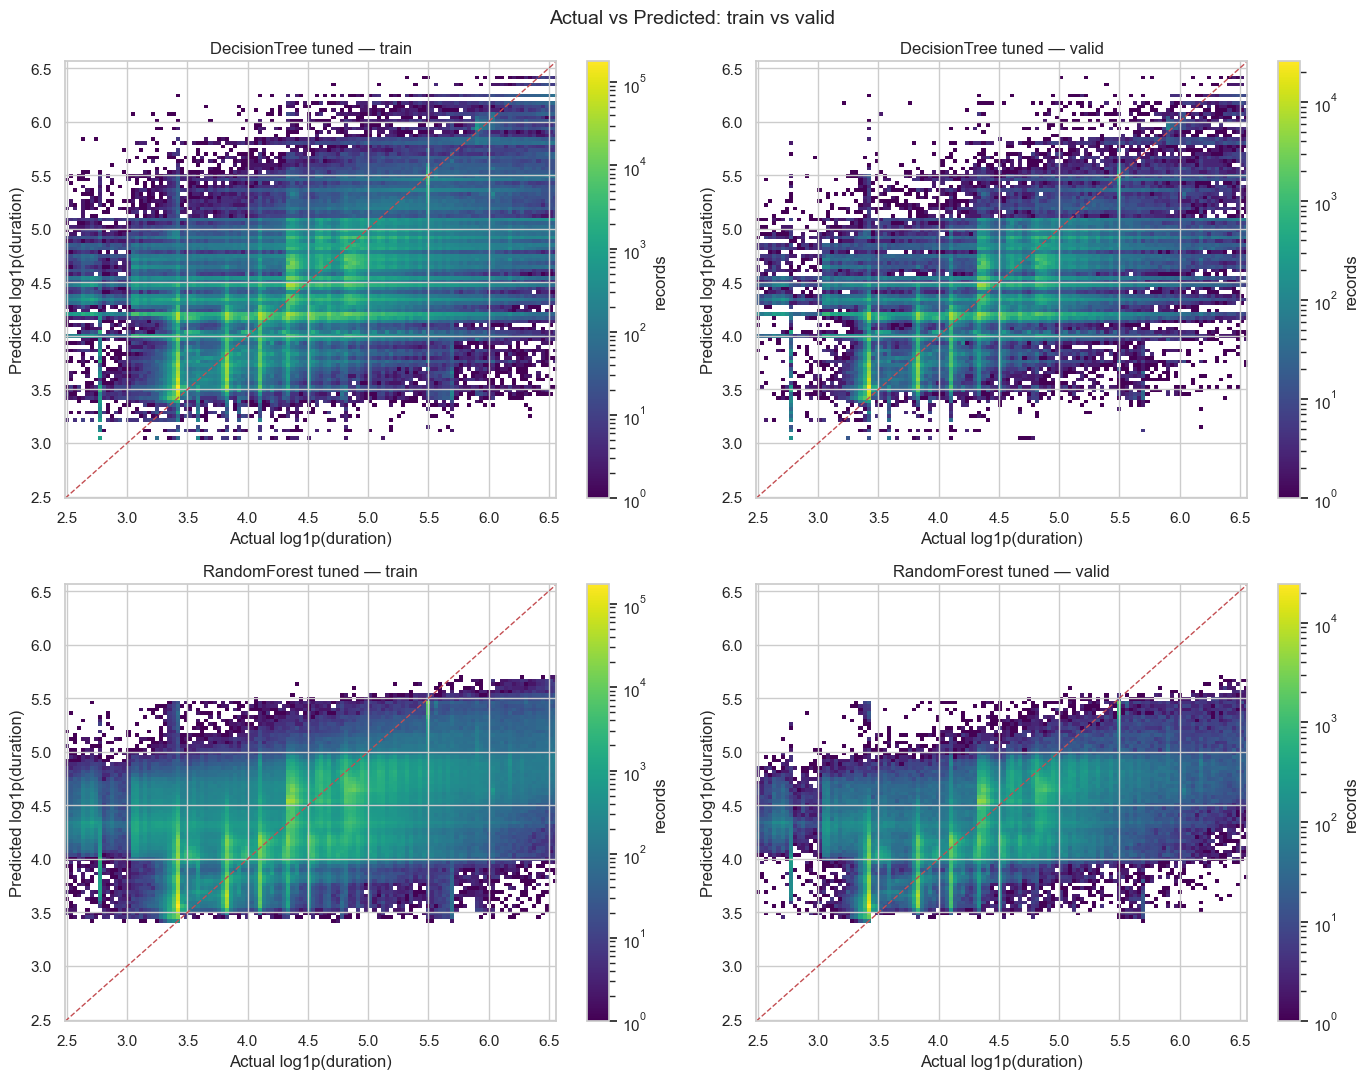

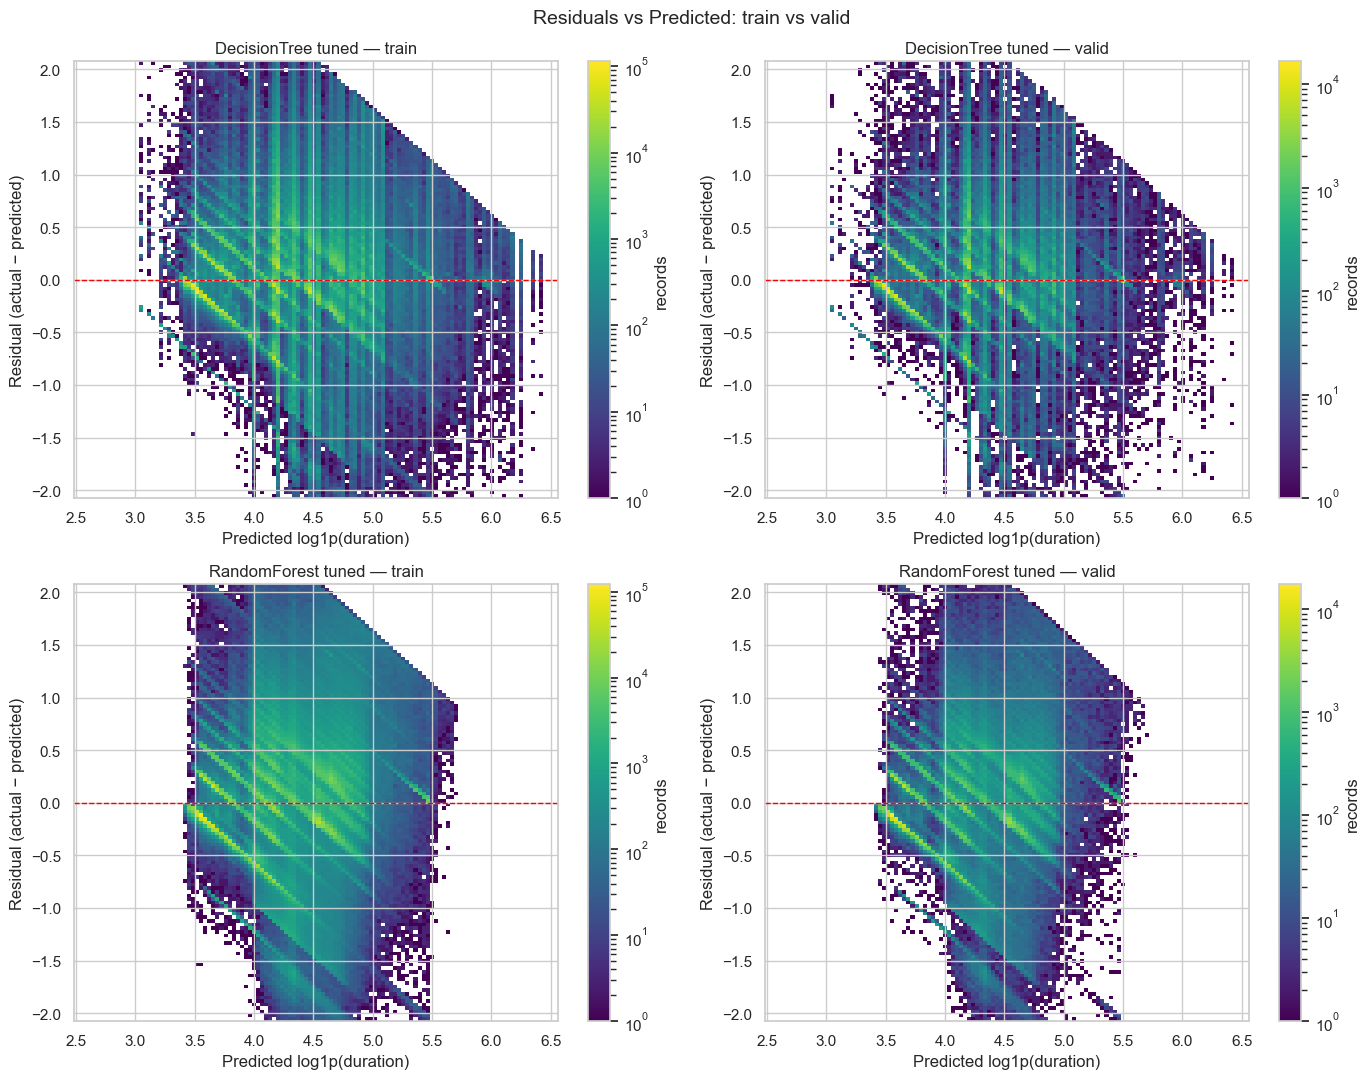

In [15]:
leader_preds = {(fam, split): with_residuals(models[name].transform(data[split])).persist(StorageLevel.MEMORY_AND_DISK)
                for fam, name in LEADERS.items() for split in ("train", "valid", "test")}
Y_RANGE = tuple(data["train"].approxQuantile("label", [0.001, 0.999], 0.0001))
res_lim = max(abs(q) for key in leader_preds if key[1] == "valid"
              for q in leader_preds[key].approxQuantile("residual", [0.001, 0.999], 0.0001))
RES_RANGE = (-res_lim, res_lim)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for i, (fam, name) in enumerate(LEADERS.items()):
    for j, split in enumerate(("train", "valid")):
        plot_actual_vs_predicted(leader_preds[(fam, split)], axes[i, j], f"{name} — {split}")
fig.suptitle("Actual vs Predicted: train vs valid", fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for i, (fam, name) in enumerate(LEADERS.items()):
    for j, split in enumerate(("train", "valid")):
        plot_residuals(leader_preds[(fam, split)], axes[i, j], f"{name} — {split}")
fig.suptitle("Residuals vs Predicted: train vs valid", fontsize=14)
plt.tight_layout()
plt.show()

## Етап 5. Фінальне оцінювання на тестовій вибірці

In [16]:
results_test = pd.DataFrame(run_parallel(lambda fam: evaluate(models[LEADERS[fam]].transform(data["test"])), LEADERS)).T
results_test.index = [LEADERS[fam] for fam in results_test.index]
results_test.T.round(4)

,DecisionTree tuned,RandomForest tuned
R² (log),0.4790,0.4583
MAE (log),0.3624,0.3792
MSE (log),0.2621,0.2725
RMSE (log),0.5120,0.5220
MAPE % (log),8.8868,9.3465
MedAE (log),0.2449,0.2538
R² (minutes),0.3472,0.2885
MAE (minutes),32.9362,34.1588
MSE (minutes),4374.1815,4767.5698
RMSE (minutes),66.1376,69.0476


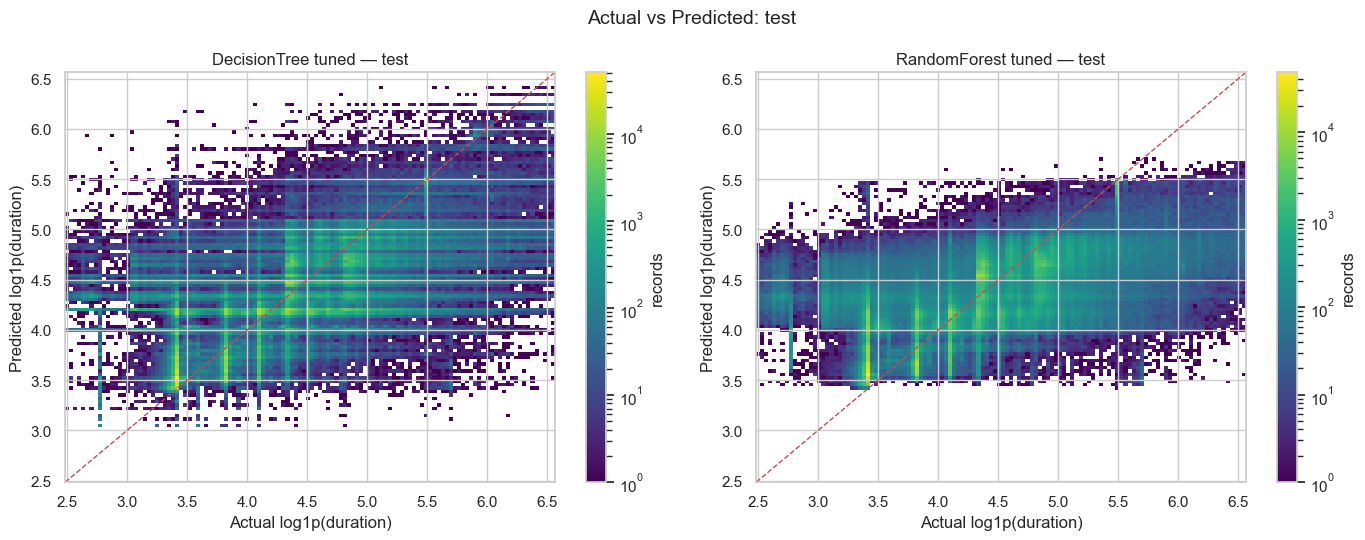

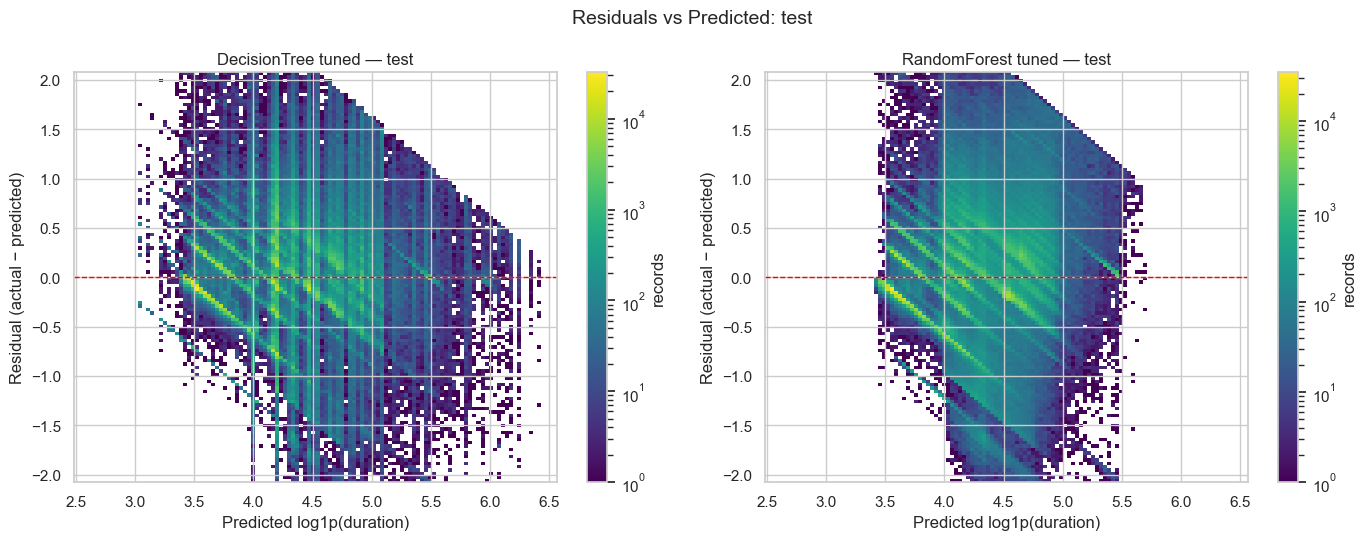

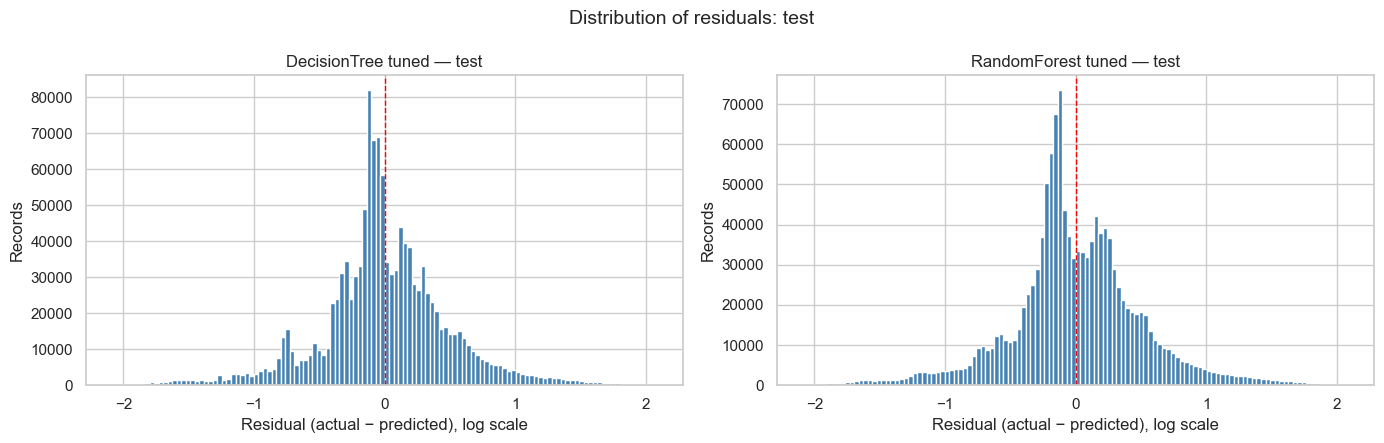

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (fam, name) in zip(axes, LEADERS.items()):
    plot_actual_vs_predicted(leader_preds[(fam, "test")], ax, f"{name} — test")
fig.suptitle("Actual vs Predicted: test", fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (fam, name) in zip(axes, LEADERS.items()):
    plot_residuals(leader_preds[(fam, "test")], ax, f"{name} — test")
fig.suptitle("Residuals vs Predicted: test", fontsize=14)
plt.tight_layout()
plt.show()

edges_res = np.linspace(*RES_RANGE, PLOT_BINS + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (fam, name) in zip(axes, LEADERS.items()):
    counts = hist1d(leader_preds[(fam, "test")], "residual", RES_RANGE)
    ax.bar(edges_res[:-1], counts, width=np.diff(edges_res), align="edge", color="steelblue")
    ax.axvline(0, color="red", ls="--", lw=1)
    ax.set(title=f"{name} — test", xlabel="Residual (actual − predicted), log scale", ylabel="Records")
fig.suptitle("Distribution of residuals: test", fontsize=14)
plt.tight_layout()
plt.show()

## Етап 6. SHAP-аналіз та інтерпретованість

Семпл ~3 000 записів test, стратифікований за децилями цілі. `shap.TreeExplainer` читає дерева Spark-моделі напряму й пояснює прогноз `log1p(тривалості)`.

In [18]:
shap_frac = min(1.0, SHAP_ROWS / N_ROWS["test"])
shap_rows = (data["test"].sampleBy("stratum", {float(s): shap_frac for s in STRATA}, seed=SEED)
             .select(vector_to_array("features").alias("x")).toPandas())
X_shap = pd.DataFrame(np.stack(shap_rows["x"].to_numpy()), columns=FEATURES)
print(f"SHAP sample: {len(X_shap):,} rows")

shap_values = {}
for fam, name in LEADERS.items():
    t0 = time.time()
    shap_values[fam] = shap.TreeExplainer(models[name])(X_shap)
    print(f"{name}: {time.time() - t0:.0f} s, SHAP values {shap_values[fam].values.shape}")

SHAP sample: 1,047 rows


/Users/yana.vyklyuk/Documents/GitHub/US-Accidents-spark-project/.venv/lib/python3.12/site-packages/shap/explainers/_tree.py:497: UserWarning: check_additivity requires us to run predictions which is not supported with spark, ignoring. Set check_additivity=False to remove this warning
  warnings.warn(


DecisionTree tuned: 11 s, SHAP values (1047, 244)


RandomForest tuned: 312 s, SHAP values (1047, 244)


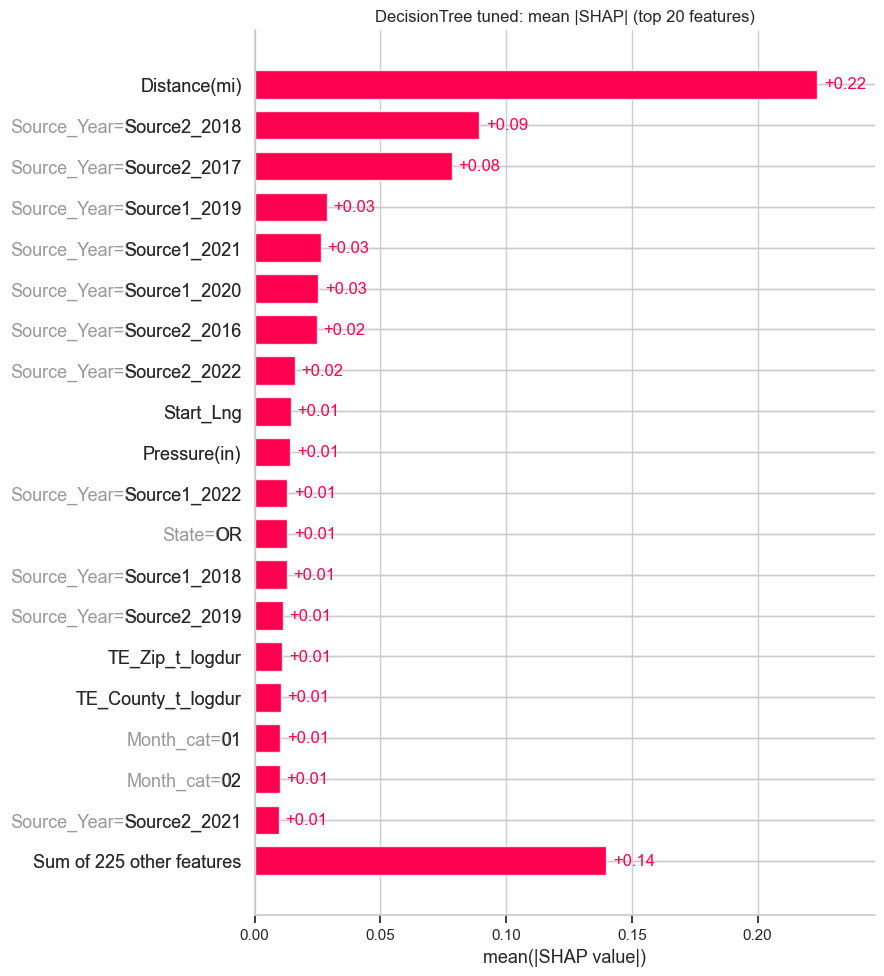

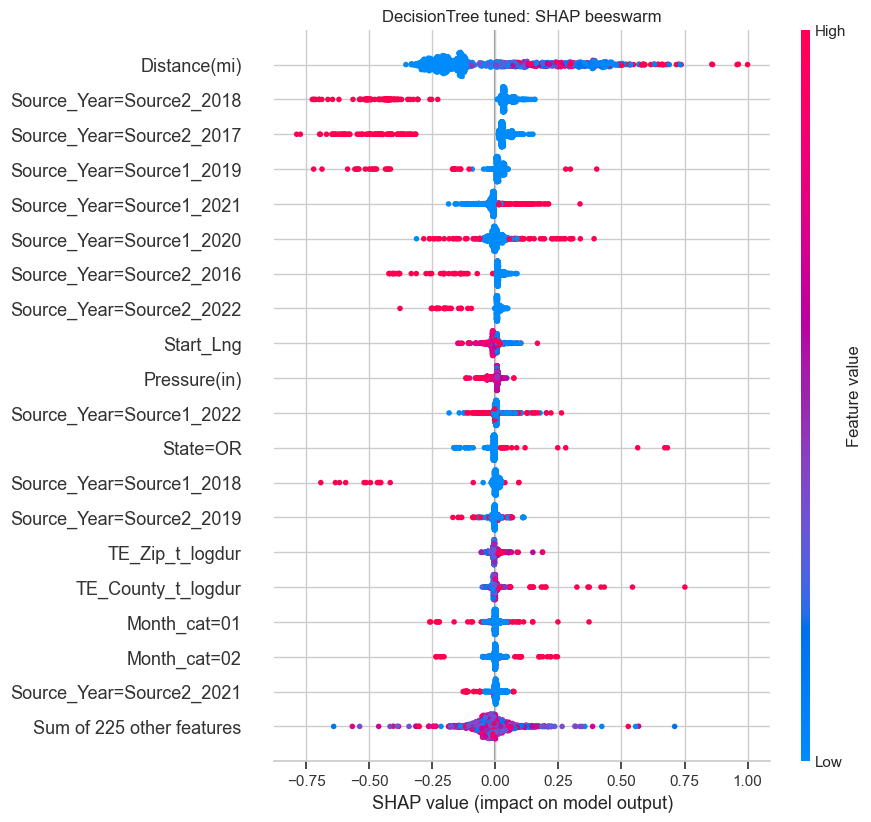

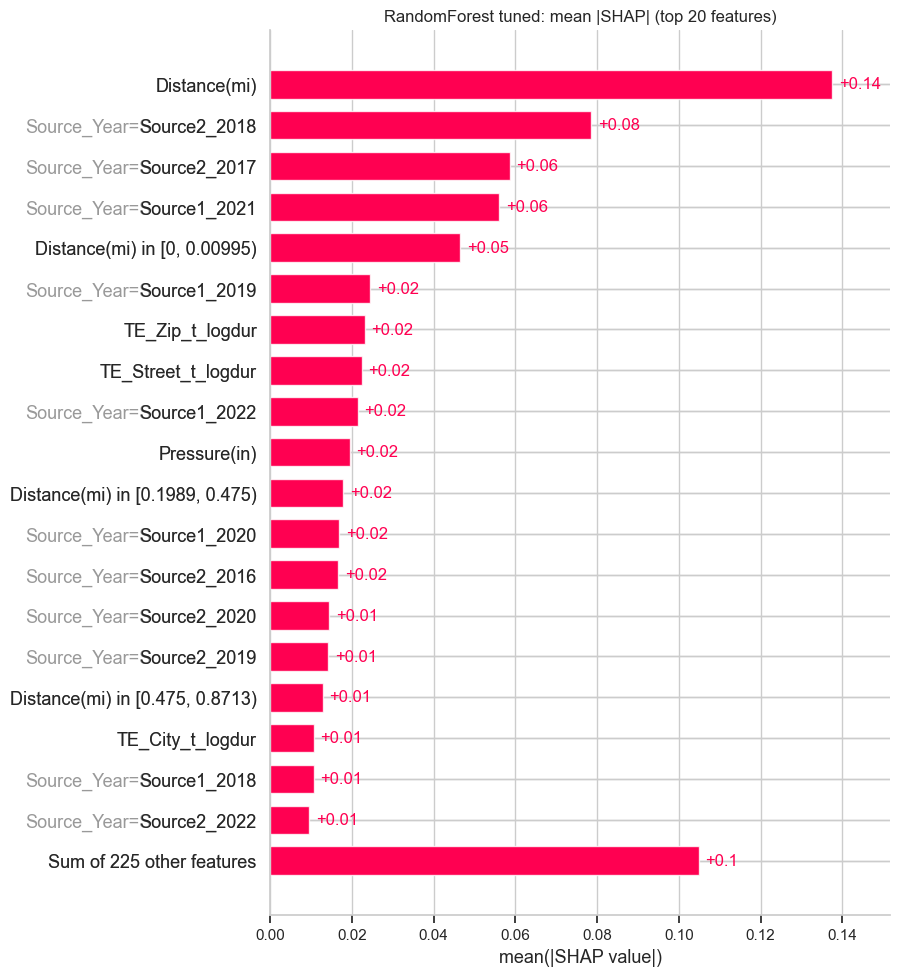

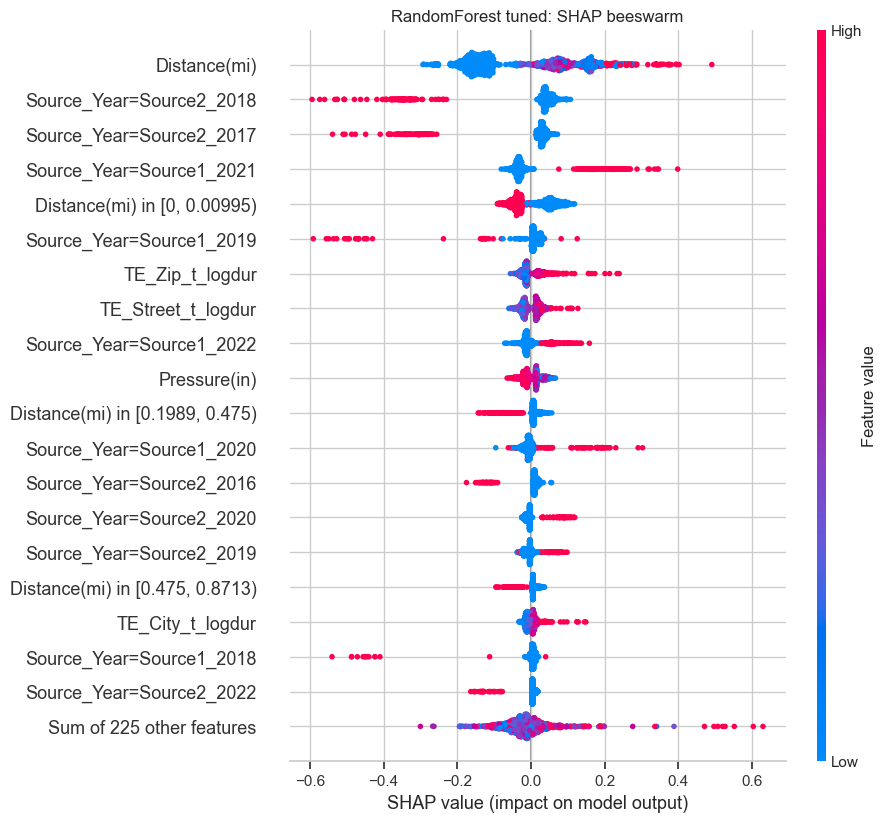

In [19]:
for fam, sv in shap_values.items():
    shap.plots.bar(sv, max_display=20, show=False)
    plt.title(f"{LEADERS[fam]}: mean |SHAP| (top 20 features)")
    plt.show()
    shap.plots.beeswarm(sv, max_display=20, show=False)
    plt.title(f"{LEADERS[fam]}: SHAP beeswarm")
    plt.show()

## Збереження лідерів

In [20]:
for fam, name in LEADERS.items():
    path = MODELS_DIR / f"{TASK}_yv_{fam}"
    models[name].write().overwrite().save(str(path))
    info = {"variant": name, "params": {p.name: v for p, v in models[name].extractParamMap().items()},
            "features": FEATURES, "target": "Log_Duration", "inverse": "expm1"}
    path.with_suffix(".json").write_text(json.dumps(info, indent=2, default=str), encoding="utf-8")
    print(f"Saved {name} -> {path}")

Saved DecisionTree tuned -> /Users/yana.vyklyuk/Documents/GitHub/US-Accidents-spark-project/data/models/regression_yv_DecisionTree


Saved RandomForest tuned -> /Users/yana.vyklyuk/Documents/GitHub/US-Accidents-spark-project/data/models/regression_yv_RandomForest


In [21]:
for df in [*data.values(), *leader_preds.values(), tune]:
    df.unpersist()
spark.stop()